## 1. Импортируем датасет

In [2]:
import pandas as pd
import os
import kagglehub

path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)
print("hbh", os.listdir(path))

file_path = os.path.join(path, "Titanic-Dataset.csv")

df = pd.read_csv(file_path)
df.head()

Path to dataset files: C:\Users\ArtAcerNitro5\.cache\kagglehub\datasets\yasserh\titanic-dataset\versions\1
hbh ['Titanic-Dataset.csv']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Анализируем данные

In [3]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Дубликаты: ", df.duplicated().sum())

(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Дубликаты:  0


мы видим очень много пропусков в колонке Age и Cabin

## 3. Визуализируем данные

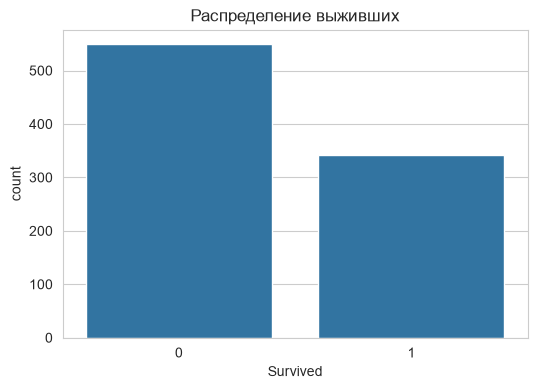

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Распределение выживших")
plt.show()

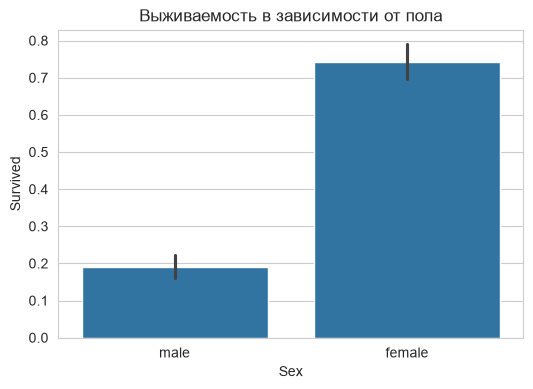

In [5]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Sex" , y="Survived")
plt.title("Выживаемость в зависимости от пола")
plt.show()

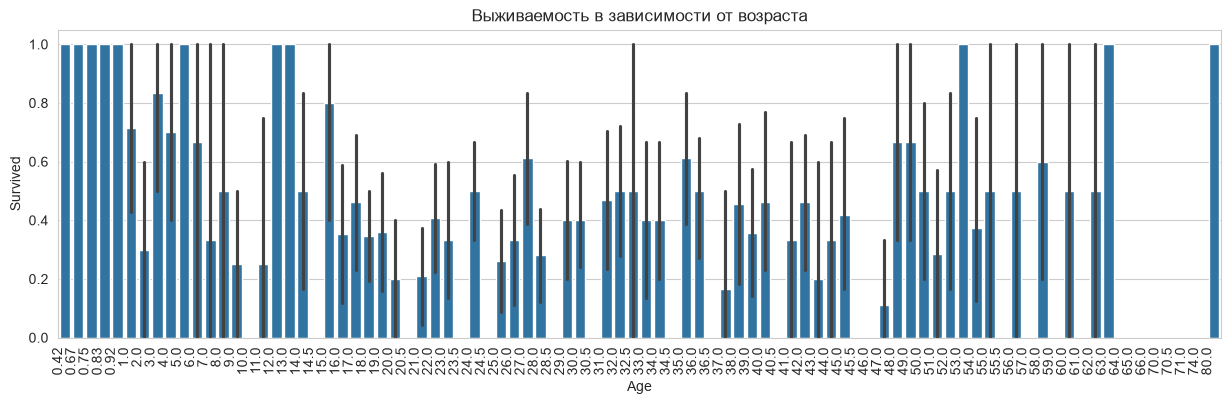

In [6]:
plt.figure(figsize=(15, 4))
sns.barplot(data=df, x="Age" , y="Survived")
plt.xticks(rotation=90, ha="right")
plt.title("Выживаемость в зависимости от возраста")
plt.show()

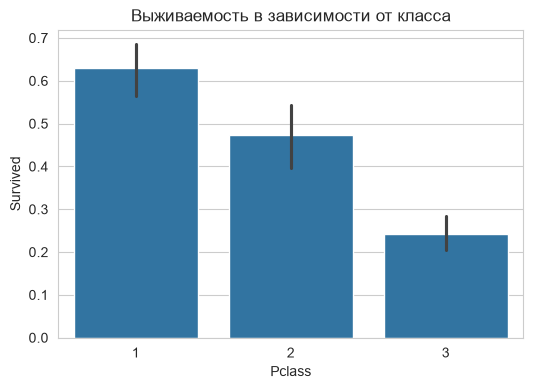

In [7]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Выживаемость в зависимости от класса")
plt.show()

## 4. Выбираем фичи

In [8]:
features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"
]
X = df[features].copy()
y = df["Survived"]
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


Мы исключили:
- PassengerId	это просто идентификатор пассажира, он не нужен
- Name	        не используем текстовые имена
- Ticket	    много уникальных значений билетов
- Cabin	        много пропусков

## 5. Делим датасет: train/validation/test

In [9]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=23, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=23, stratify=y_train_val
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (569, 7)
Validation: (143, 7)
Test: (179, 7)


## 6. Заполняем пропуски

In [10]:
X_train_p = X_train.copy()
X_val_p = X_val.copy()
X_test_p = X_test.copy()

age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

for part in [X_train_p, X_val_p, X_test_p]:
    part["Age"] = part["Age"].fillna(age_median)
    part["Embarked"] = part["Embarked"].fillna(embarked_mode)

print(X_train_p.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## 7. Категориальные значения -> в числовые

In [11]:
categorical = ["Sex", "Embarked", "Pclass"]

X_train_p = pd.get_dummies(X_train_p, columns=categorical, dtype=int)
X_val_p = pd.get_dummies(X_val_p, columns=categorical, dtype=int)
X_test_p = pd.get_dummies(X_test_p, columns=categorical, dtype=int)

X_val_p = X_val_p.reindex(columns=X_train_p.columns, fill_value=0)
X_test_p = X_test_p.reindex(columns=X_val_p.columns, fill_value=0)

## 8. Scaling

Для деревьев данные уже готовы, но для SVM и KNN нужно делать Scaling

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_p)
X_val_scaled = scaler.transform(X_val_p)
X_test_scaled = scaler.transform(X_test_p)

## 9. Baseline

Accuracy: 0.6153846153846154
Precision: 0.0
Recall: 0.0
F1: 0.0


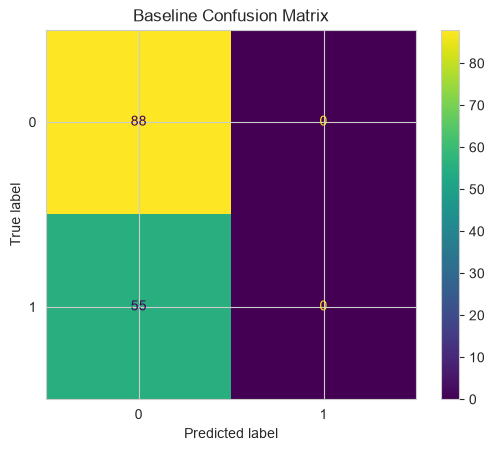

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_p, y_train)
baseline_pred = baseline.predict(X_val_p)

print("Accuracy:", accuracy_score(y_val, baseline_pred))
print("Precision:", precision_score(y_val, baseline_pred, zero_division=0))
print("Recall:", recall_score(y_val, baseline_pred))
print("F1:", f1_score(y_val, baseline_pred))

ConfusionMatrixDisplay.from_predictions(y_val, baseline_pred)
plt.title("Baseline Confusion Matrix")
plt.show()

## 10. Decision Tree

In [14]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=23)

tree.fit(X_train_p, y_train)

train_pred = tree.predict(X_train_p)
val_pred = tree.predict(X_val_p)

print("Depth:", tree.get_depth())
print("Train F1:", f1_score(y_train, train_pred))
print("Validation F1:", f1_score(y_val, val_pred))

Depth: 17
Train F1: 0.971830985915493
Validation F1: 0.6666666666666666


для глубины 17 дерево переобучилось => пытаемся найти оптимальную грубину дерева

## 11. Анализируем оптимальную глубину дерева

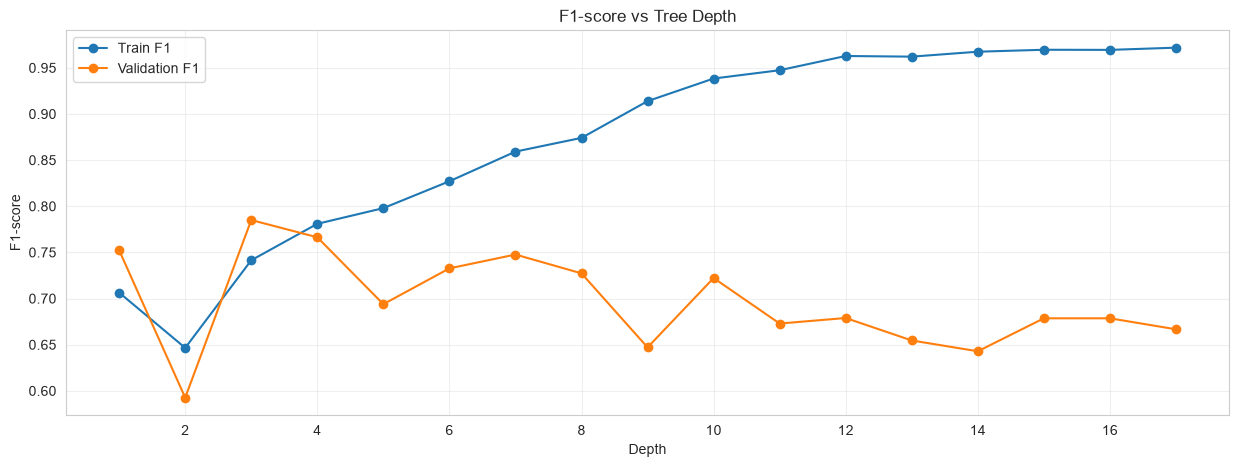

In [16]:
depths = range(1, tree.get_depth() + 1)

train_scores = []
val_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=23
    )

    model.fit(X_train_p, y_train)

    train_scores.append(
        f1_score(y_train, model.predict(X_train_p))
    )

    val_scores.append(
        f1_score(y_val, model.predict(X_val_p))
    )

plt.figure(figsize=(15, 5))

plt.plot(depths, train_scores, marker="o", label="Train F1")
plt.plot(depths, val_scores, marker="o", label="Validation F1")

plt.xlabel("Depth")
plt.ylabel("F1-score")
plt.title("F1-score vs Tree Depth")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree.fit(X_train_p, y_train)

tree_pred = tree.predict(X_val_p)

print("Train F1:", f1_score(y_train, tree.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, tree_pred))

Train F1: 0.780952380952381
Validation F1: 0.7428571428571429


## 12. Random Forest

In [41]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100,
    random_state=23,
    n_jobs=-1
)

forest.fit(X_train_p, y_train)

print("Train F1:", f1_score(y_train, forest.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, forest.predict(X_val_p)))

Train F1: 0.9720930232558139
Validation F1: 0.7592592592592593


## 13. Random Forest - анализ глубины деревьев

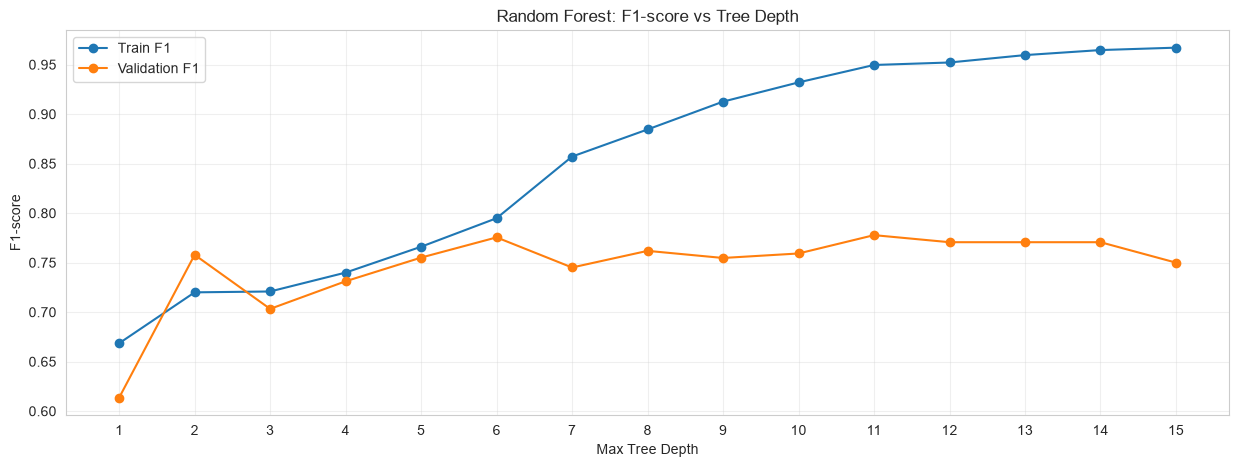

In [45]:
depths = range(1, 16)

forest_train_scores = []
forest_val_scores = []

for depth in depths:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=23,
        n_jobs=-1
    )

    model.fit(X_train_p, y_train)

    forest_train_scores.append(
        f1_score(y_train, model.predict(X_train_p))
    )

    forest_val_scores.append(
        f1_score(y_val, model.predict(X_val_p))
    )

plt.figure(figsize=(15, 5))

plt.plot(depths, forest_train_scores, marker="o", label="Train F1")
plt.plot(depths, forest_val_scores, marker="o", label="Validation F1")

plt.xlabel("Max Tree Depth")
plt.ylabel("F1-score")
plt.title("Random Forest: F1-score vs Tree Depth")

plt.xticks(depths)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

лучшая глубина деревьев - 6

In [48]:
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=23
)

tree.fit(X_train_p, y_train)

tree_pred = tree.predict(X_val_p)

print("Train F1:", f1_score(y_train, tree.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, tree_pred))

Train F1: 0.780952380952381
Validation F1: 0.7663551401869159


## 14. Random Forest - анализ кол-ва деревьев

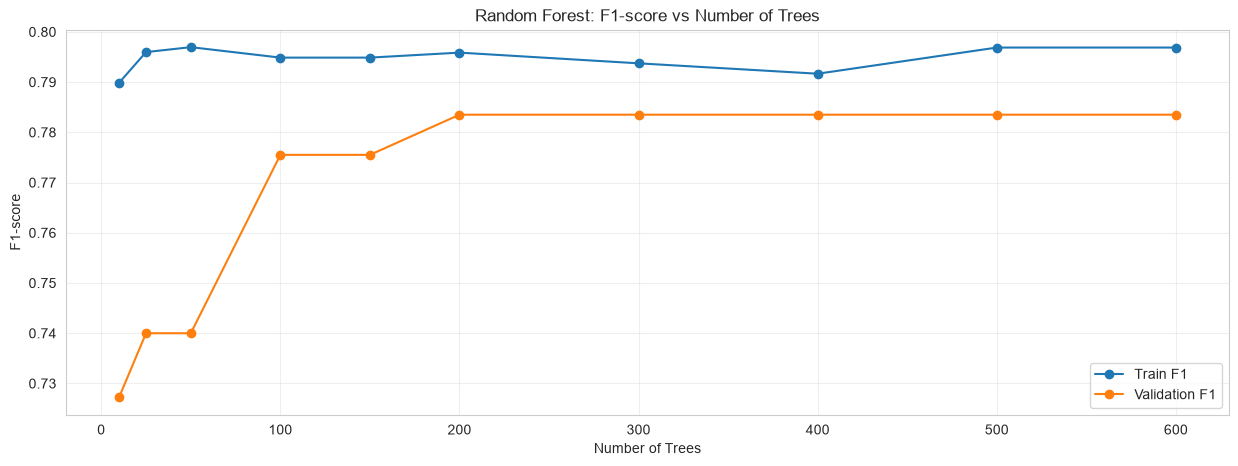

In [47]:
n_trees = [10, 25, 50, 100, 150, 200, 300, 400, 500, 600]

train_scores = []
val_scores = []

for n in n_trees:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=6,
        random_state=23,
        n_jobs=-1
    )

    model.fit(X_train_p, y_train)

    train_scores.append(
        f1_score(y_train, model.predict(X_train_p))
    )

    val_scores.append(
        f1_score(y_val, model.predict(X_val_p))
    )

plt.figure(figsize=(15, 5))

plt.plot(n_trees, train_scores, marker="o", label="Train F1")
plt.plot(n_trees, val_scores, marker="o", label="Validation F1")

plt.xlabel("Number of Trees")
plt.ylabel("F1-score")
plt.title("Random Forest: F1-score vs Number of Trees")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

оставляем 200 деревьев

In [49]:
forest = RandomForestClassifier(
    n_estimators=400,
    max_depth=6,
    random_state=23,
    n_jobs=-1
)

forest.fit(X_train_p, y_train)

forest_pred = forest.predict(X_val_p)

print("Train F1:", f1_score(y_train, forest.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, forest_pred))

Train F1: 0.7916666666666666
Validation F1: 0.7835051546391752


## 15. Gradient Boosting

In [50]:
from sklearn.ensemble import GradientBoostingClassifier

boosting = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

boosting.fit(X_train_p, y_train)

print("Train F1:", f1_score(y_train, boosting.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, boosting.predict(X_val_p)))

Train F1: 0.9451073985680191
Validation F1: 0.7924528301886793


тоже переобучилась => исследуем параметры n_estimators и learning_rate

## 16. Gradient Boosting - анализ кол-ва деревьев

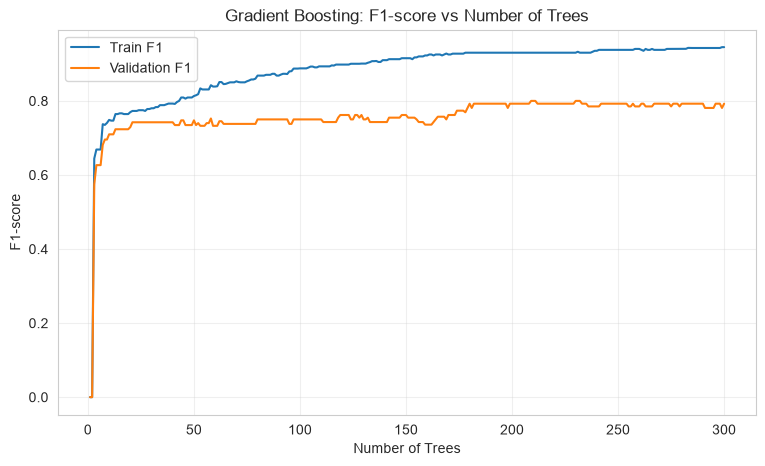

In [51]:
train_scores = []
val_scores = []

for pred in boosting.staged_predict(X_train_p):
    train_scores.append(f1_score(y_train, pred))

for pred in boosting.staged_predict(X_val_p):
    val_scores.append(f1_score(y_val, pred))

n_trees = range(1, 301)

plt.figure(figsize=(9, 5))

plt.plot(n_trees, train_scores, label="Train F1")
plt.plot(n_trees, val_scores, label="Validation F1")

plt.xlabel("Number of Trees")
plt.ylabel("F1-score")
plt.title("Gradient Boosting: F1-score vs Number of Trees")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [52]:
best_n = val_scores.index(max(val_scores)) + 1

print("Best number of trees:", best_n)
print("Best Validation F1:", max(val_scores))

Best number of trees: 209
Best Validation F1: 0.8


оставляем кол-во деревьев = 210

## 17. Gradient Boosting - анализ параметра learning_rate

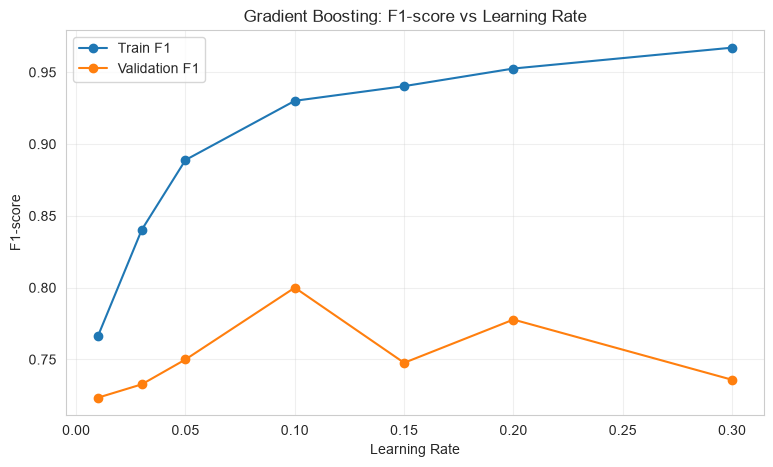

In [53]:
learning_rates = [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.3]

lr_train_scores = []
lr_val_scores = []

for lr in learning_rates:
    model = GradientBoostingClassifier(
        n_estimators=210,
        learning_rate=lr,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train_p, y_train)

    lr_train_scores.append(
        f1_score(y_train, model.predict(X_train_p))
    )

    lr_val_scores.append(
        f1_score(y_val, model.predict(X_val_p))
    )

plt.figure(figsize=(9, 5))

plt.plot(learning_rates, lr_train_scores,
         marker="o", label="Train F1")

plt.plot(learning_rates, lr_val_scores,
         marker="o", label="Validation F1")

plt.xlabel("Learning Rate")
plt.ylabel("F1-score")
plt.title("Gradient Boosting: F1-score vs Learning Rate")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

фиксируем learning rate = 0,1

In [54]:
boosting = GradientBoostingClassifier(
    n_estimators=210,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

boosting.fit(X_train_p, y_train)

boosting_pred = boosting.predict(X_val_p)

print("Train F1:", f1_score(y_train, boosting.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, boosting_pred))

Train F1: 0.9301204819277108
Validation F1: 0.8


## 18. Support Vector Machine

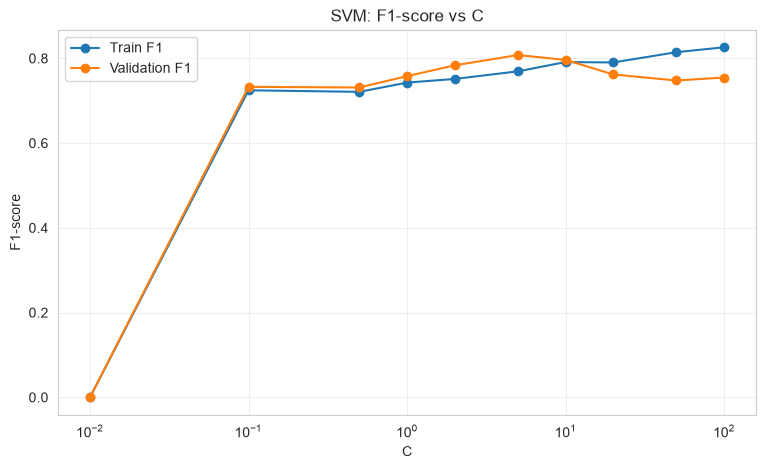

In [55]:
from sklearn.svm import SVC

c_values = [0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]

svm_train_scores = []
svm_val_scores = []

for c in c_values:
    model = SVC(kernel="rbf", C=c)

    model.fit(X_train_scaled, y_train)

    svm_train_scores.append(
        f1_score(y_train, model.predict(X_train_scaled))
    )

    svm_val_scores.append(
        f1_score(y_val, model.predict(X_val_scaled))
    )

plt.figure(figsize=(9, 5))

plt.plot(c_values, svm_train_scores, marker="o", label="Train F1")
plt.plot(c_values, svm_val_scores, marker="o", label="Validation F1")

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("F1-score")
plt.title("SVM: F1-score vs C")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

выбираем C = 10

In [56]:
svm = SVC(
    kernel="rbf",
    C=10
)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_val_scaled)

print("Train F1:", f1_score(y_train, svm.predict(X_train_scaled)))
print("Validation F1:", f1_score(y_val, svm_pred))

Train F1: 0.7911547911547911
Validation F1: 0.7962962962962963


## 19. KNN - анализ параметра k

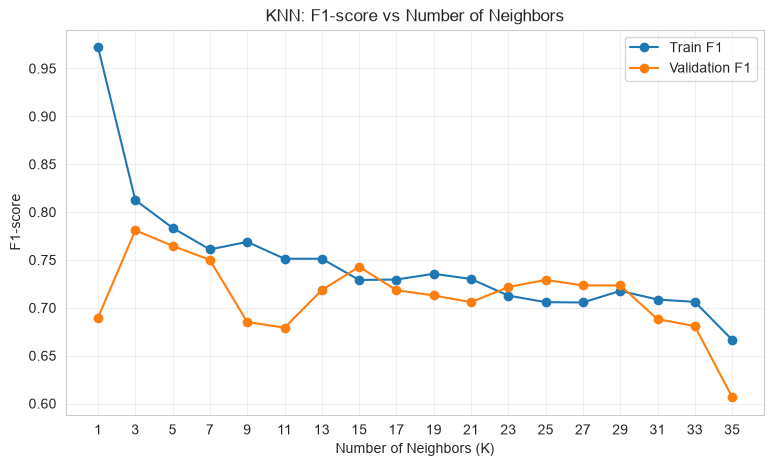

In [57]:
from sklearn.neighbors import KNeighborsClassifier

k_values = range(1, 36, 2)

knn_train_scores = []
knn_val_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    knn_train_scores.append(
        f1_score(y_train, model.predict(X_train_scaled))
    )

    knn_val_scores.append(
        f1_score(y_val, model.predict(X_val_scaled))
    )

plt.figure(figsize=(9, 5))

plt.plot(k_values, knn_train_scores, marker="o", label="Train F1")
plt.plot(k_values, knn_val_scores, marker="o", label="Validation F1")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("F1-score")
plt.title("KNN: F1-score vs Number of Neighbors")

plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

k = 3 зафиксировал

In [58]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_val_scaled)

print("Train F1:", f1_score(y_train, knn.predict(X_train_scaled)))
print("Validation F1:", f1_score(y_val, knn_pred))

Train F1: 0.8125
Validation F1: 0.780952380952381


## 20. Сравнение моделей

In [59]:
predictions = {
    "Baseline": baseline_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred,
    "Gradient Boosting": boosting_pred,
    "SVM": svm_pred,
    "KNN": knn_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred)
    })

val_table = pd.DataFrame(results).sort_values(
    "F1", ascending=False
)

display(val_table.round(3))

,Model,Accuracy,Precision,Recall,F1
3,Gradient Boosting,0.853,0.840,0.764,0.800
4,SVM,0.846,0.811,0.782,0.796
2,Random Forest,0.853,0.905,0.691,0.784
5,KNN,0.839,0.820,0.745,0.781
1,Decision Tree,0.825,0.788,0.745,0.766
0,Baseline,0.615,0.000,0.000,0.000


## 21. Используем тестовую выборку на моделях

In [60]:
models = {
    "Baseline": baseline,
    "Decision Tree": tree,
    "Random Forest": forest,
    "Gradient Boosting": boosting,
    "SVM": svm,
    "KNN": knn
}

test_predictions = {}
test_results = []

for name, model in models.items():

    if name in ["SVM", "KNN"]:
        pred = model.predict(X_test_scaled)
    else:
        pred = model.predict(X_test_p)

    test_predictions[name] = pred

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

test_table = pd.DataFrame(test_results)
test_table = test_table.sort_values("F1", ascending=False)

display(test_table.round(3))

,Model,Accuracy,Precision,Recall,F1
2,Random Forest,0.844,0.902,0.667,0.767
3,Gradient Boosting,0.821,0.814,0.696,0.750
4,SVM,0.832,0.882,0.652,0.750
1,Decision Tree,0.816,0.790,0.710,0.748
5,KNN,0.810,0.807,0.667,0.730
0,Baseline,0.615,0.000,0.000,0.000


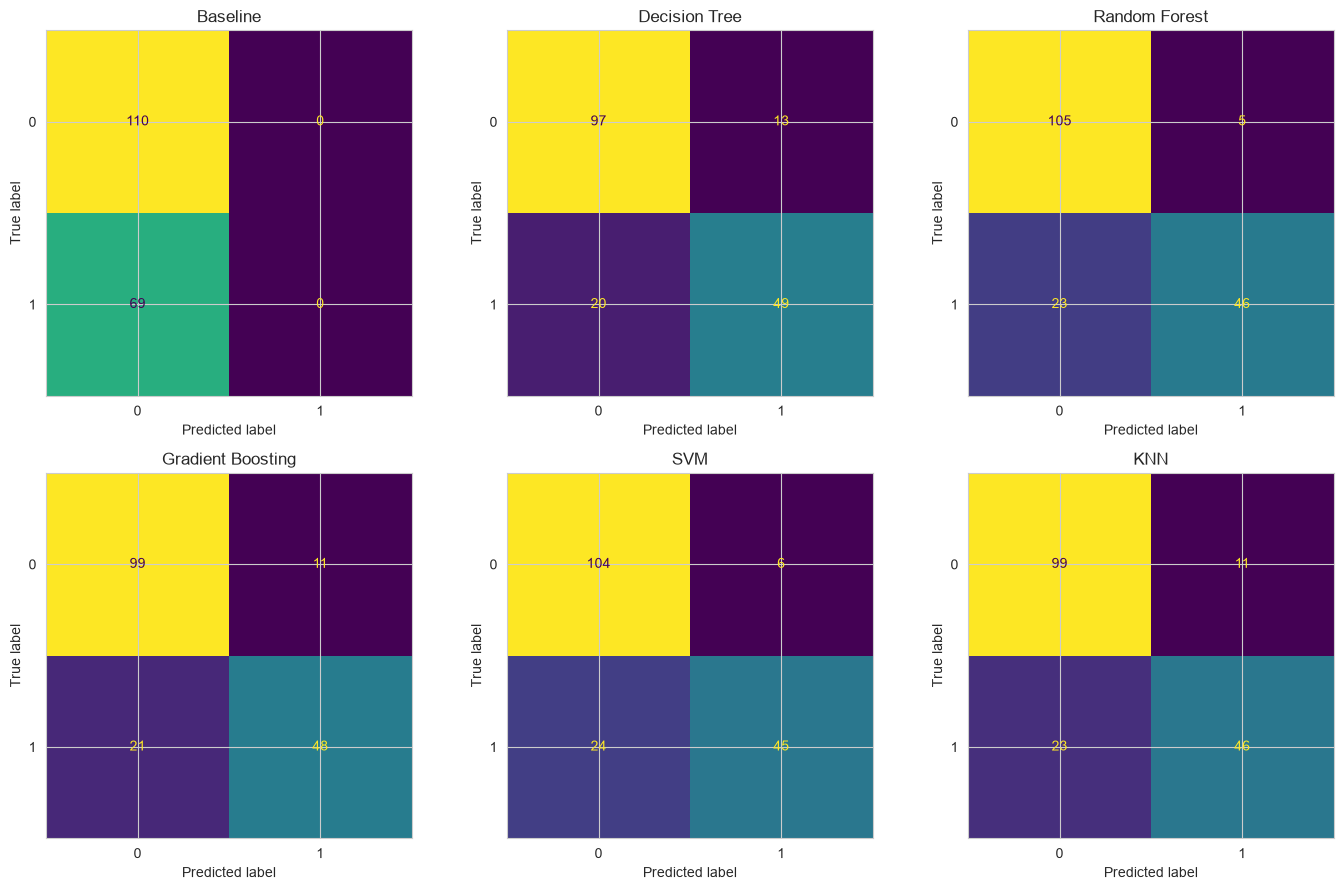

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (name, pred) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=[0, 1],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 22. Feature Importance

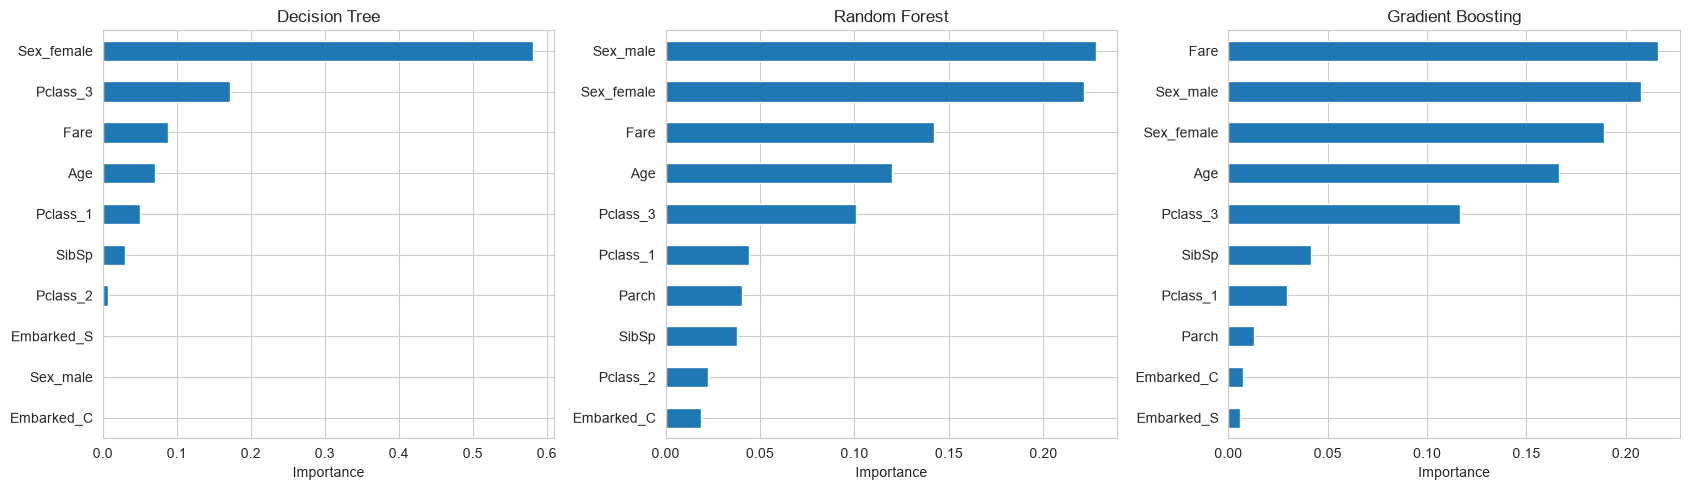

In [63]:
tree_models = {
    "Decision Tree": tree,
    "Random Forest": forest,
    "Gradient Boosting": boosting
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, tree_models.items()):

    importance = pd.Series(
        model.feature_importances_,
        index=X_train_p.columns
    )

    importance = importance.sort_values().tail(10)

    importance.plot(kind="barh", ax=ax)

    ax.set_title(name)
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()

## 23. Ошибки победившей модели на validation

In [65]:
best_name = val_table.iloc[0]["Model"]

print("Best model:", best_name)

best_pred = test_predictions[best_name]

errors = X_test.copy()

errors["Actual"] = y_test
errors["Predicted"] = best_pred
errors["Error"] = errors["Actual"] != errors["Predicted"]

display(errors[errors["Error"]].head(10))

Best model: Gradient Boosting


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Actual,Predicted,Error
821,3,male,27.0,0,0,8.6625,S,1,0,True
455,3,male,29.0,0,0,7.8958,C,1,0,True
826,3,male,NaN,0,0,56.4958,S,0,1,True
357,2,female,38.0,0,0,13.0000,S,0,1,True
14,3,female,14.0,0,0,7.8542,S,0,1,True
192,3,female,19.0,1,0,7.8542,S,1,0,True
207,3,male,26.0,0,0,18.7875,C,1,0,True
709,3,male,NaN,1,1,15.2458,C,1,0,True
630,1,male,80.0,0,0,30.0000,S,1,0,True
559,3,female,36.0,1,0,17.4000,S,1,0,True
